In [ ]:

# STEP 1.1 — Install project dependencies

%pip install -q pandas numpy matplotlib seaborn scikit-learn tensorflow ucimlrepo


In [ ]:

# STEP 1.2 — Upload and load the dataset in Google Colab

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from google.colab import files

uploaded = files.upload()

csv_files = [
    filename for filename in uploaded
    if filename.lower().endswith(".csv")
]

if not csv_files:
    raise ValueError(
        "Please upload the dataset as a CSV file."
    )

csv_path = csv_files[0]
df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("File:", csv_path)
print("Dataset shape:", df.shape)

display(df.head())


Saving framingham.csv to framingham.csv
Dataset loaded successfully!
File: framingham.csv
Dataset shape: (4240, 16)


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [ ]:

# STEP 1.3 — Initial dataset inspection

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

print("\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
if "TenYearCHD" in df.columns:
    display(df["TenYearCHD"].value_counts(dropna=False))
else:
    print(
        "Target column TenYearCHD was not found. "
        "Check the CSV column names before continuing."
    )

print("\nAssignment field-count check:")
if df.shape[1] >= 15:
    print("PASS: At least 15 fields are present.")
else:
    print("WARNING: Dataset has fewer than 15 fields.")


Number of rows: 4240
Number of columns: 16

Column names:
['male', 'age', 'education', 'currentSmoker', 'cigsPerDay', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose', 'TenYearCHD']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4240 entries, 0 to 4239
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4240 non-null   int64  
 1   age              4240 non-null   int64  
 2   education        4135 non-null   float64
 3   currentSmoker    4240 non-null   int64  
 4   cigsPerDay       4211 non-null   float64
 5   BPMeds           4187 non-null   float64
 6   prevalentStroke  4240 non-null   int64  
 7   prevalentHyp     4240 non-null   int64  
 8   diabetes         4240 non-null   int64  
 9   totChol          4190 non-null   float64
 10  sysBP            4240 non-null   float64
 11  diaBP   

,count,mean,std,min,25%,50%,75%,max
male,4240.0,0.429245,0.495027,0.00,0.00,0.0,1.00,1.0
age,4240.0,49.580189,8.572942,32.00,42.00,49.0,56.00,70.0
education,4135.0,1.979444,1.019791,1.00,1.00,2.0,3.00,4.0
currentSmoker,4240.0,0.494104,0.500024,0.00,0.00,0.0,1.00,1.0
cigsPerDay,4211.0,9.005937,11.922462,0.00,0.00,0.0,20.00,70.0
BPMeds,4187.0,0.029615,0.169544,0.00,0.00,0.0,0.00,1.0
prevalentStroke,4240.0,0.005896,0.076569,0.00,0.00,0.0,0.00,1.0
prevalentHyp,4240.0,0.310613,0.462799,0.00,0.00,0.0,1.00,1.0
diabetes,4240.0,0.025708,0.158280,0.00,0.00,0.0,0.00,1.0
totChol,4190.0,236.699523,44.591284,107.00,206.00,234.0,263.00,696.0



Missing values per column:


,Missing Values
male,0
age,0
education,105
currentSmoker,0
cigsPerDay,29
BPMeds,53
prevalentStroke,0
prevalentHyp,0
diabetes,0
totChol,50



Duplicate rows: 0

Target distribution:


,count
TenYearCHD,
0,3596
1,644



Assignment field-count check:
PASS: At least 15 fields are present.


In [ ]:

# STEP 2.1: Inspect dataset structure

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)


Dataset shape: (4240, 16)

Column names:
['male', 'age', 'education', 'currentSmoker', 'cigsPerDay', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose', 'TenYearCHD']

Missing values in each column:
male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64

Number of duplicate rows:
0

Data types:
male                 int64
age                  int64
education          float64
currentSmoker        int64
cigsPerDay         float64
BPMeds             float64
prevalentStroke      int64
prevalentHyp         int64
diabetes             int64
totChol            float64
sysBP              float64
diaBP           

In [ ]:

# STEP 2.2: Standardize column names

df.columns = (
    df.columns
    .str.strip()
    .str.replace(" ", "_", regex=False)
)

# Remove exact duplicate rows
duplicates_before = df.duplicated().sum()
df = df.drop_duplicates().copy()

print("Duplicate rows found:", duplicates_before)
print("Shape after duplicate removal:", df.shape)


Duplicate rows found: 0
Shape after duplicate removal: (4240, 16)


In [ ]:

# STEP 2.3: Validate the prediction target

target = "TenYearCHD"

if target not in df.columns:
    print("Target column not found.")
    print("Available columns:", df.columns.tolist())
else:
    print("Target distribution:")
    print(df[target].value_counts(dropna=False))

    print("\nTarget proportions:")
    print(df[target].value_counts(normalize=True, dropna=False).round(3))

    print("\nMissing target values:", df[target].isnull().sum())


Target distribution:
TenYearCHD
0    3596
1     644
Name: count, dtype: int64

Target proportions:
TenYearCHD
0    0.848
1    0.152
Name: proportion, dtype: float64

Missing target values: 0


In [ ]:

# STEP 2.4: Remove records with unknown target labels

if target in df.columns:
    rows_before = len(df)
    df = df.dropna(subset=[target]).copy()

    print("Rows removed due to missing target:", rows_before - len(df))
    print("Remaining rows:", len(df))
    print("\nRemaining missing values:")
    print(df.isnull().sum().sort_values(ascending=False))


Rows removed due to missing target: 0
Remaining rows: 4240

Remaining missing values:
glucose            388
education          105
BPMeds              53
totChol             50
cigsPerDay          29
BMI                 19
heartRate            1
male                 0
prevalentHyp         0
prevalentStroke      0
age                  0
currentSmoker        0
diaBP                0
sysBP                0
diabetes             0
TenYearCHD           0
dtype: int64


In [ ]:

# STEP 2.5: Detect potential numeric outliers using the IQR rule

numeric_cols = df.select_dtypes(include="number").columns.tolist()

# Exclude the target from predictor outlier checks
numeric_predictors = [col for col in numeric_cols if col != target]

outlier_summary = []

for col in numeric_predictors:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary.append({
        "Feature": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Potential Outliers": int(count)
    })

outlier_df = pd.DataFrame(outlier_summary)
print(outlier_df.to_string(index=False))


        Feature  Lower Bound  Upper Bound  Potential Outliers
           male       -1.500        2.500                   0
            age       21.000       77.000                   0
      education       -2.000        6.000                   0
  currentSmoker       -1.500        2.500                   0
     cigsPerDay      -30.000       50.000                  12
         BPMeds        0.000        0.000                 124
prevalentStroke        0.000        0.000                  25
   prevalentHyp       -1.500        2.500                   0
       diabetes        0.000        0.000                 109
        totChol      120.500      348.500                  56
          sysBP       76.500      184.500                 126
          diaBP       52.500      112.500                  77
            BMI       15.615       35.495                  97
      heartRate       45.500      105.500                  76
        glucose       47.000      111.000                 188


In [ ]:

# STEP 2.6: Save the cleaned working dataset

df.to_csv("heart_disease_cleaned.csv", index=False)

print("Cleaned working dataset saved.")
print("Final shape:", df.shape)
print("Exact duplicate rows remaining:", df.duplicated().sum())
print("Missing target values remaining:", df[target].isnull().sum())


Cleaned working dataset saved.
Final shape: (4240, 16)
Exact duplicate rows remaining: 0
Missing target values remaining: 0


In [ ]:

from google.colab import files
files.download("heart_disease_cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")
os.makedirs("heart_disease_figures", exist_ok=True)

target = "TenYearCHD"

print("Dataset shape:", df.shape)
print("Target available:", target in df.columns)
print("Columns:", df.columns.tolist())


Dataset shape: (4240, 16)
Target available: True
Columns: ['male', 'age', 'education', 'currentSmoker', 'cigsPerDay', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose', 'TenYearCHD']


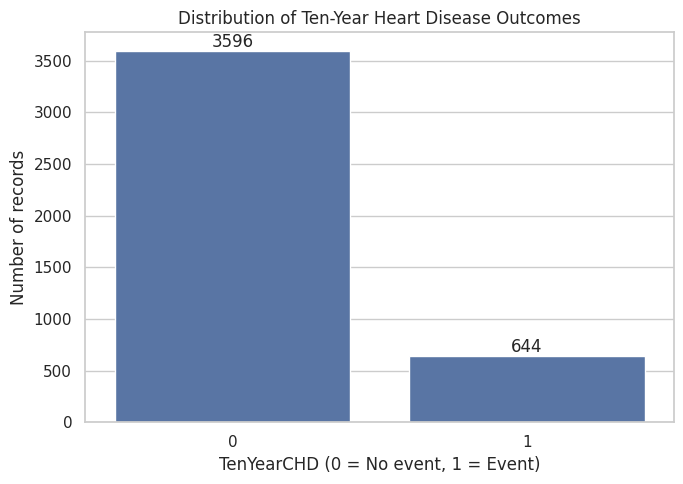

TenYearCHD
0    84.81
1    15.19
Name: proportion, dtype: float64


In [ ]:

plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x=target)
ax.set_title("Distribution of Ten-Year Heart Disease Outcomes")
ax.set_xlabel("TenYearCHD (0 = No event, 1 = Event)")
ax.set_ylabel("Number of records")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.savefig("heart_disease_figures/01_target_distribution.png", dpi=300)
plt.show()

print(df[target].value_counts(normalize=True).mul(100).round(2))


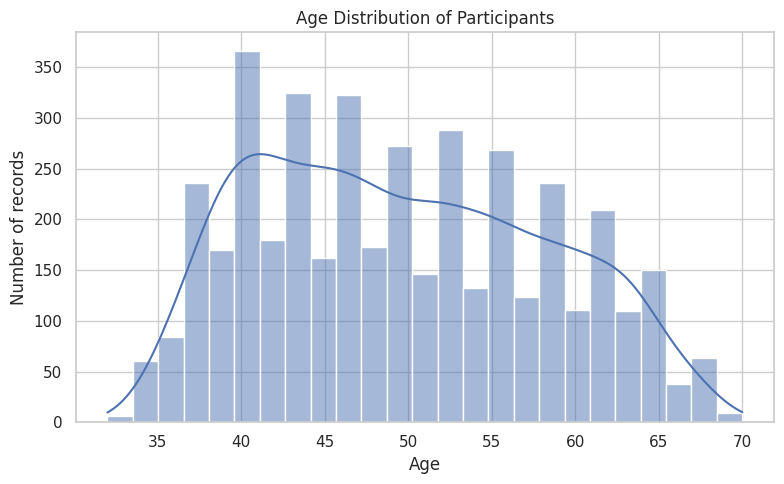

In [ ]:

age_col = next(
    (c for c in df.columns if c.lower() == "age"),
    None
)

if age_col:
    plt.figure(figsize=(8, 5))
    sns.histplot(data=df, x=age_col, bins=25, kde=True)
    plt.title("Age Distribution of Participants")
    plt.xlabel("Age")
    plt.ylabel("Number of records")
    plt.tight_layout()
    plt.savefig("heart_disease_figures/02_age_distribution.png", dpi=300)
    plt.show()
else:
    print("No Age column found. Check df.columns.tolist().")


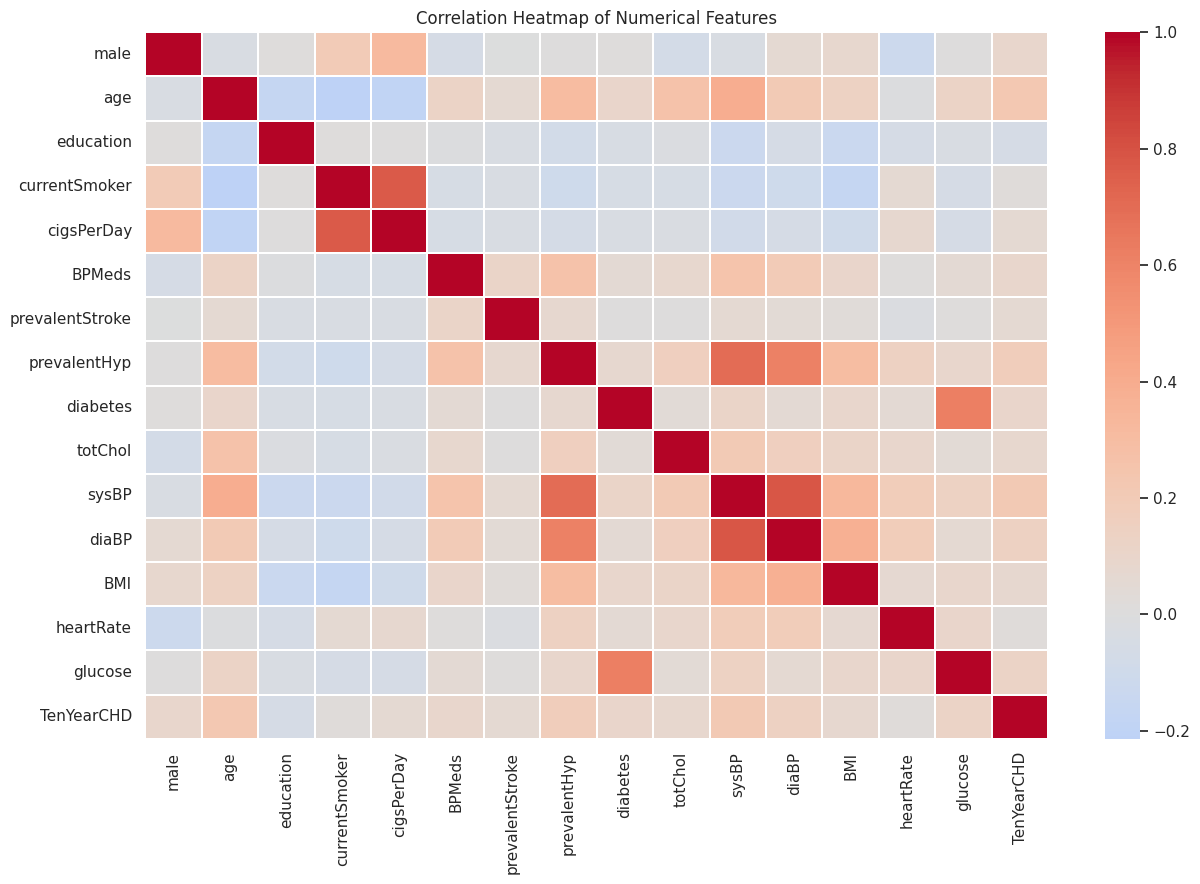

In [ ]:

numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(13, 9))
sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    center=0,
    annot=False,
    linewidths=0.3
)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.savefig("heart_disease_figures/03_correlation_heatmap.png", dpi=300)
plt.show()


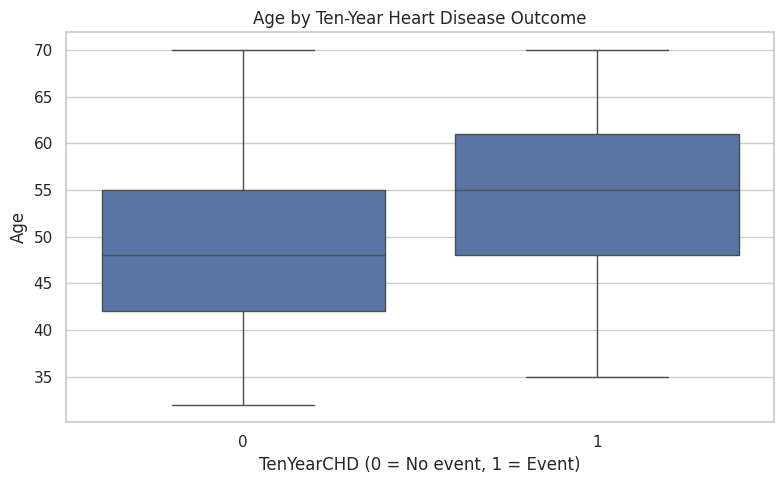

In [ ]:

if age_col:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x=target, y=age_col)
    plt.title("Age by Ten-Year Heart Disease Outcome")
    plt.xlabel("TenYearCHD (0 = No event, 1 = Event)")
    plt.ylabel("Age")
    plt.tight_layout()
    plt.savefig("heart_disease_figures/04_age_by_outcome.png", dpi=300)
    plt.show()


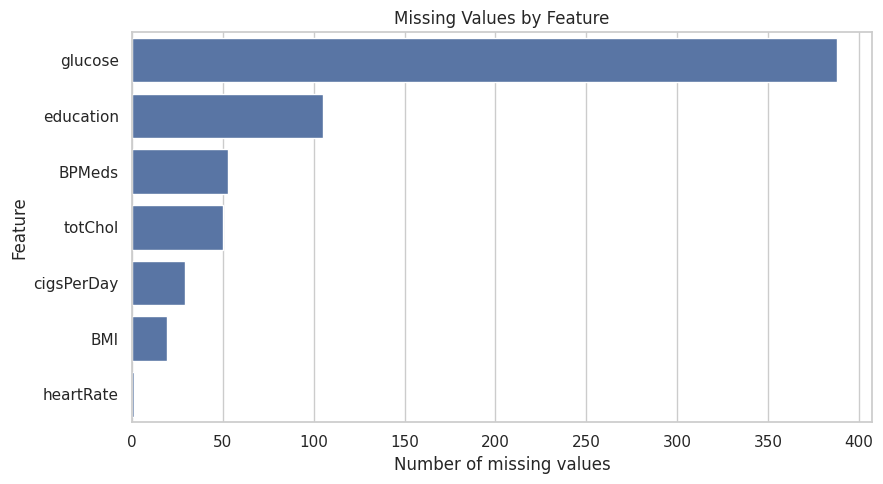

In [ ]:

# Visualization 5: Missing Values

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(9, 5))

if len(missing) > 0:
    sns.barplot(x=missing.values, y=missing.index)
    plt.xlabel("Number of missing values")
    plt.ylabel("Feature")
    plt.title("Missing Values by Feature")
else:
    plt.text(
        0.5, 0.5,
        "No missing values found in the current dataset",
        ha="center",
        va="center",
        fontsize=12
    )
    plt.axis("off")

plt.tight_layout()
plt.savefig(
    "heart_disease_figures/05_missing_values.png",
    dpi=300
)
plt.show()


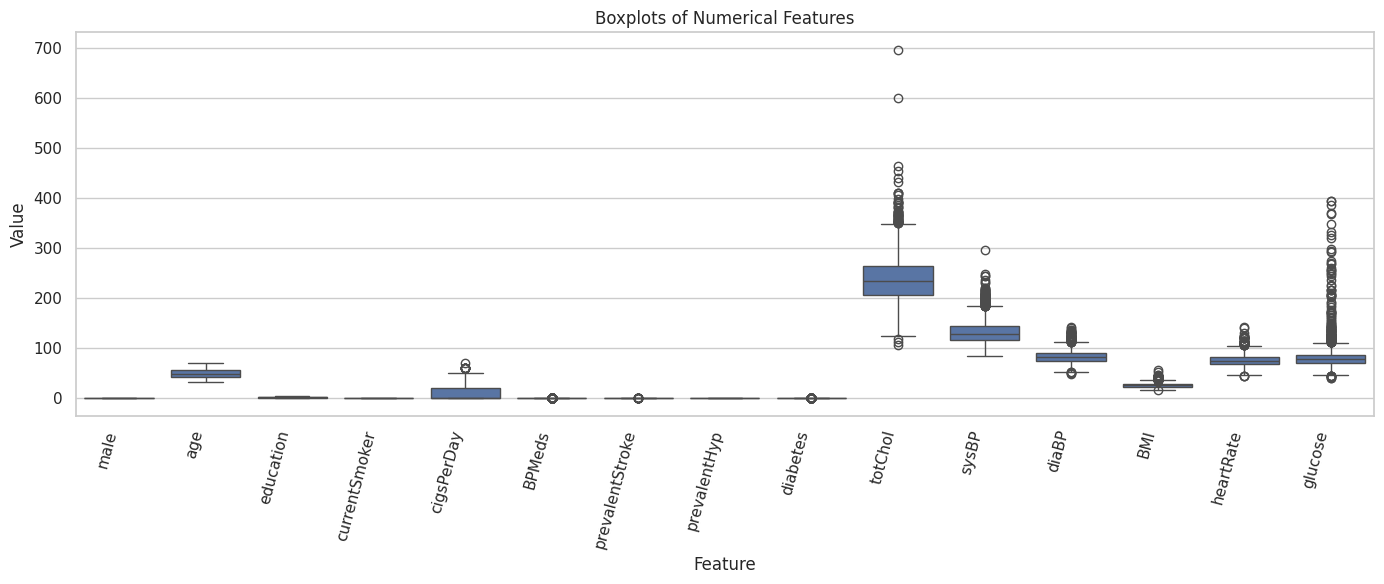

In [ ]:

numeric_features = [
    c for c in df.select_dtypes(include="number").columns
    if c != target
]

if numeric_features:
    plot_df = df[numeric_features].melt(
        var_name="Feature",
        value_name="Value"
    )

    plt.figure(figsize=(14, 6))
    sns.boxplot(data=plot_df, x="Feature", y="Value")
    plt.xticks(rotation=75, ha="right")
    plt.title("Boxplots of Numerical Features")
    plt.tight_layout()
    plt.savefig("heart_disease_figures/06_feature_boxplots.png", dpi=300)
    plt.show()


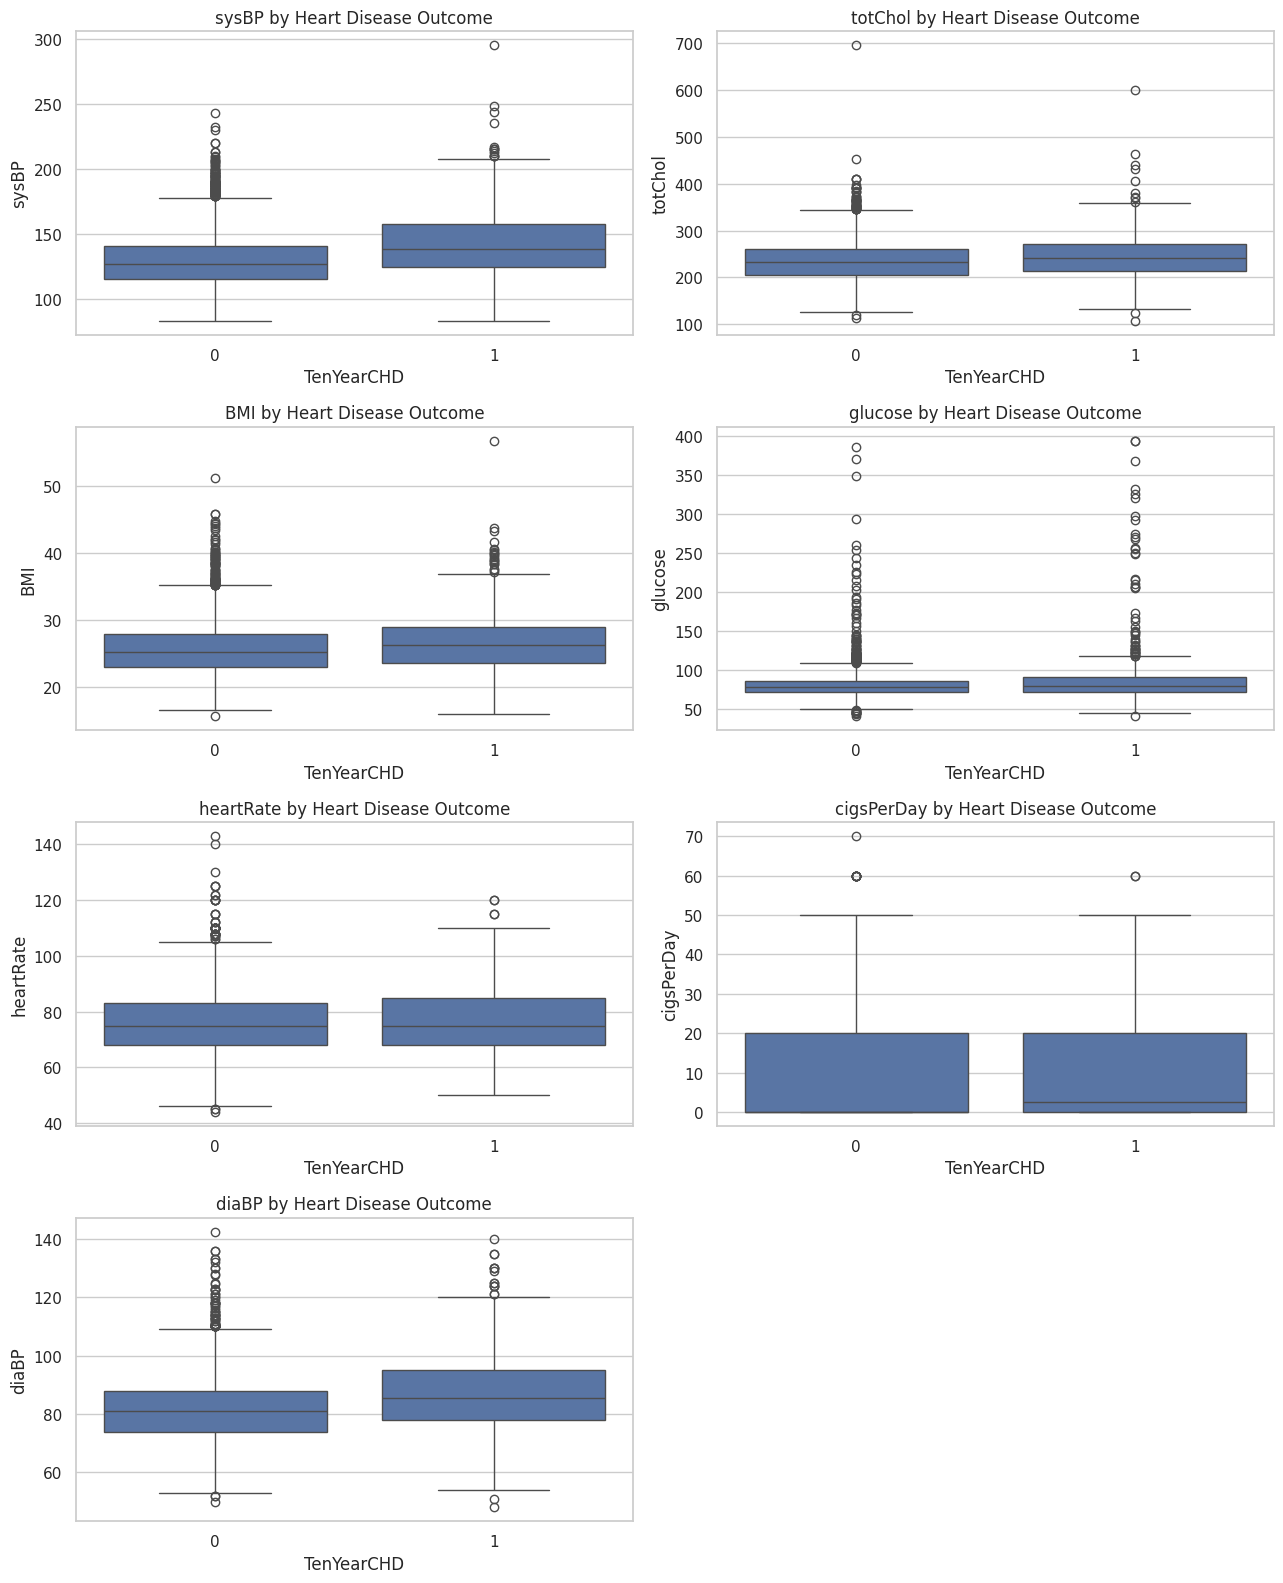

In [ ]:

candidate_features = [
    "sysBP", "totChol", "BMI", "glucose",
    "heartRate", "cigsPerDay", "diaBP"
]

available_features = [
    c for c in candidate_features if c in df.columns
]

if available_features:
    ncols = 2
    nrows = int(np.ceil(len(available_features) / ncols))

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(13, 4 * nrows)
    )
    axes = np.array(axes).reshape(-1)

    for ax, col in zip(axes, available_features):
        sns.boxplot(data=df, x=target, y=col, ax=ax)
        ax.set_title(f"{col} by Heart Disease Outcome")
        ax.set_xlabel("TenYearCHD")

    for ax in axes[len(available_features):]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.savefig(
        "heart_disease_figures/07_risk_factors_by_outcome.png",
        dpi=300
    )
    plt.show()
else:
    print("No matching risk-factor columns found.")


In [ ]:

import shutil
from google.colab import files

shutil.make_archive(
    "heart_disease_figures",
    "zip",
    "heart_disease_figures"
)

files.download("heart_disease_figures.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# STEP 4.1: Separate features (X) and target (y)

from sklearn.model_selection import train_test_split

target = "TenYearCHD"

# Remove rows with missing target values
model_df = df.dropna(subset=[target]).copy()

X = model_df.drop(columns=[target])
y = model_df[target].astype(int)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())


Feature shape: (4240, 15)
Target shape: (4240,)

Target distribution:
TenYearCHD
0    3596
1     644
Name: count, dtype: int64


In [ ]:

# STEP 4.2: Split the dataset

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).round(3))


Training samples: 2968
Validation samples: 636
Test samples: 636

Training class proportions:
TenYearCHD
0    0.848
1    0.152
Name: proportion, dtype: float64


In [ ]:

# STEP 4.3: Preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify column types using the training set
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Numerical columns: median imputation + scaling
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical columns: most-frequent imputation + one-hot encoding
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Convert sparse matrices to dense arrays when necessary
X_train_processed = (
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed
)
X_val_processed = (
    X_val_processed.toarray()
    if hasattr(X_val_processed, "toarray")
    else X_val_processed
)
X_test_processed = (
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else X_test_processed
)

print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)
print("Processed test shape:", X_test_processed.shape)
print("Remaining missing training values:", np.isnan(X_train_processed).sum())


Processed training shape: (2968, 15)
Processed validation shape: (636, 15)
Processed test shape: (636, 15)
Remaining missing training values: 0


In [ ]:

# STEP 4.5: Build and train the MLP

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight

tf.keras.utils.set_random_seed(42)

classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)
class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

model = keras.Sequential([
    layers.Input(shape=(X_train_processed.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.20),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="auc")
    ]
)

model.summary()

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    X_train_processed,
    y_train.to_numpy(),
    validation_data=(X_val_processed, y_val.to_numpy()),
    epochs=100,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,137 (12.25 KB)

 Trainable params: 3,137 (12.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.5576 - auc: 0.6097 - loss: 0.6788 - val_accuracy: 0.5550 - val_auc: 0.6816 - val_loss: 0.6921
Epoch 2/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6230 - auc: 0.7036 - loss: 0.6298 - val_accuracy: 0.5865 - val_auc: 0.6941 - val_loss: 0.6694
Epoch 3/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6304 - auc: 0.7048 - loss: 0.6334 - val_accuracy: 0.5975 - val_auc: 0.6961 - val_loss: 0.6668
Epoch 4/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6378 - auc: 0.7241 - loss: 0.6145 - val_accuracy: 0.6053 - val_auc: 0.6947 - val_loss: 0.6564
Epoch 5/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6425 - auc: 0.7214 - loss: 0.6175 - val_accuracy: 0.6211 - val_auc: 0.6908 - val_loss: 0.6424
Epoch 6/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6543 - auc: 0.7342 - loss: 0.6051 - val_accuracy: 0.6242 - val_auc: 0.6949 - val_loss: 0.6309
Epoch 7/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/

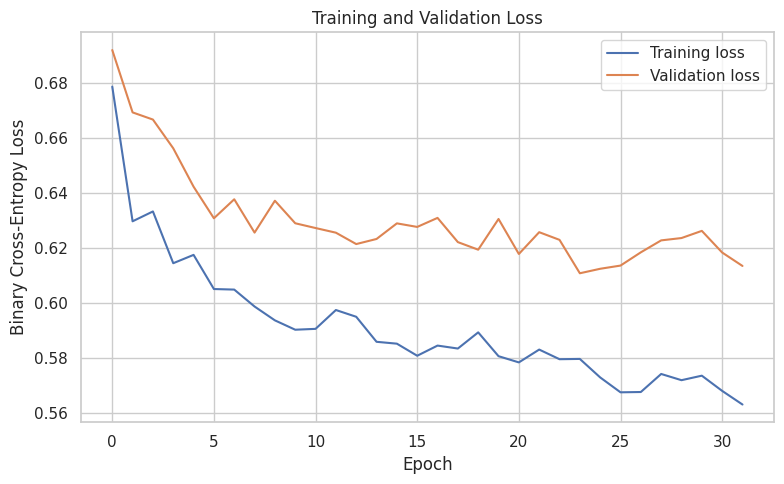

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.tight_layout()
plt.savefig("heart_disease_figures/08_training_validation_loss.png", dpi=300)
plt.show()


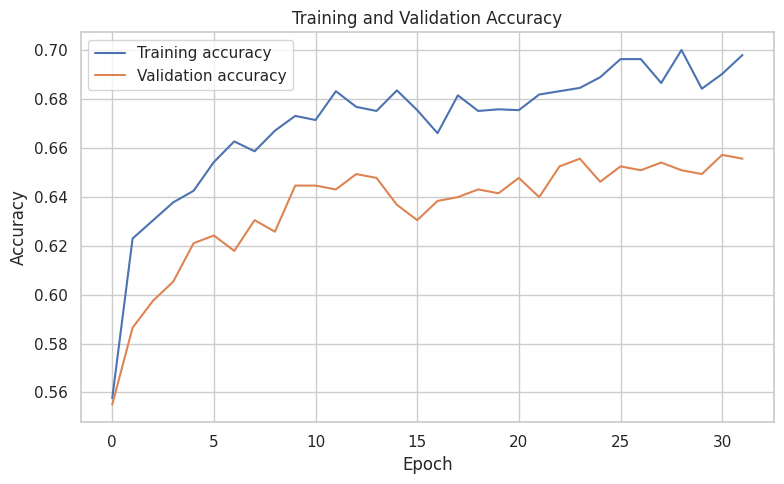

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig("heart_disease_figures/09_training_validation_accuracy.png", dpi=300)
plt.show()


In [ ]:

# STEP 5.1: Generate test predictions

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

y_prob = model.predict(X_test_processed).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Test Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Test Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("Test F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("Test ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Test Accuracy: 0.6651
Test Precision: 0.2377
Test Recall: 0.5521
Test F1-score: 0.3323
Test ROC-AUC: 0.6878

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.69      0.78       540
           1       0.24      0.55      0.33        96

    accuracy                           0.67       636
   macro avg       0.57      0.62      0.55       636
weighted avg       0.80      0.67      0.71       636



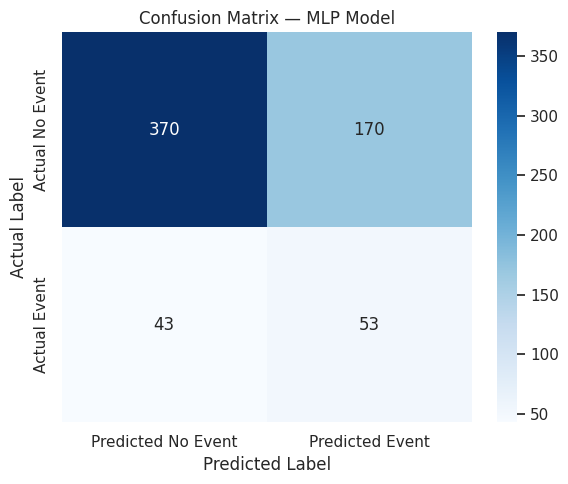

In [ ]:

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted No Event", "Predicted Event"],
    yticklabels=["Actual No Event", "Actual Event"]
)

plt.title("Confusion Matrix — MLP Model")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.savefig("heart_disease_figures/10_confusion_matrix.png", dpi=300)
plt.show()


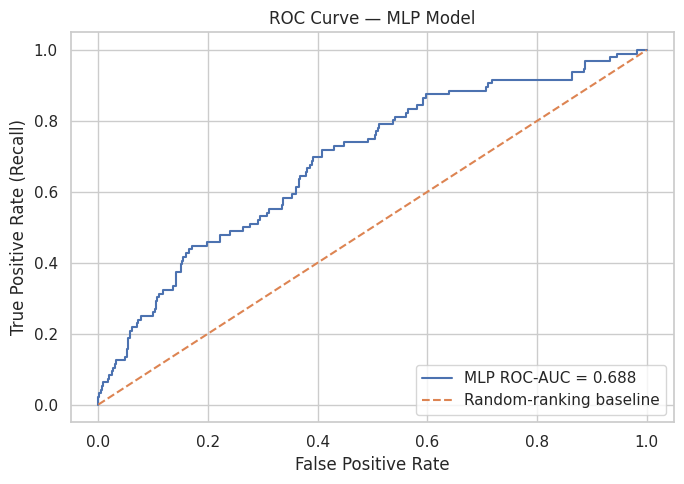

In [ ]:

from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"MLP ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random-ranking baseline")

plt.title("ROC Curve — MLP Model")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("heart_disease_figures/11_roc_curve.png", dpi=300)
plt.show()


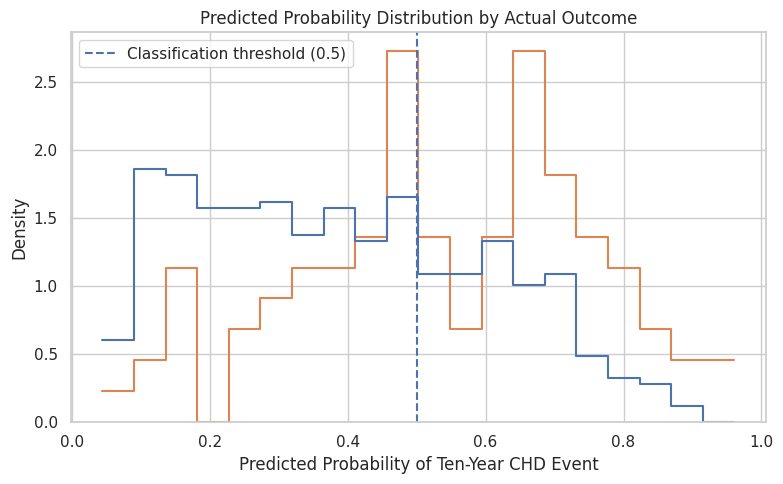

In [ ]:

prob_df = pd.DataFrame({
    "Actual Outcome": y_test.to_numpy(),
    "Predicted Probability": y_prob
})

plt.figure(figsize=(8, 5))
sns.histplot(
    data=prob_df,
    x="Predicted Probability",
    hue="Actual Outcome",
    bins=20,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)

plt.axvline(0.5, linestyle="--", label="Classification threshold (0.5)")
plt.title("Predicted Probability Distribution by Actual Outcome")
plt.xlabel("Predicted Probability of Ten-Year CHD Event")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.savefig("heart_disease_figures/12_prediction_probability_distribution.png", dpi=300)
plt.show()


In [ ]:

# STEP 5.5: Compare classification thresholds on validation data

val_prob = model.predict(X_val_processed).ravel()

threshold_results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
    val_pred = (val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, val_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
print(threshold_df.round(3).to_string(index=False))


20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
 Threshold  Precision  Recall  F1-score
       0.3      0.200   0.897     0.327
       0.4      0.219   0.773     0.341
       0.5      0.252   0.639     0.362
       0.6      0.267   0.402     0.321
       0.7      0.296   0.216     0.250


In [ ]:

# STEP 5.6: Logistic regression baseline

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

baseline = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

baseline.fit(X_train_processed, y_train)

baseline_prob = baseline.predict_proba(X_test_processed)[:, 1]
baseline_pred = (baseline_prob >= 0.5).astype(int)

comparison_df = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, baseline_pred),
        "Precision": precision_score(y_test, baseline_pred, zero_division=0),
        "Recall": recall_score(y_test, baseline_pred, zero_division=0),
        "F1-score": f1_score(y_test, baseline_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, baseline_prob)
    },
    {
        "Model": "MLP Neural Network",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }
])

print(comparison_df.round(3).to_string(index=False))


              Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
Logistic Regression     0.682      0.257   0.583     0.357    0.697
 MLP Neural Network     0.665      0.238   0.552     0.332    0.688


In [ ]:

# STEP 6: Export model and evaluation results

model.save("heart_disease_mlp.keras")
comparison_df.to_csv("heart_disease_model_comparison.csv", index=False)
threshold_df.to_csv("heart_disease_threshold_comparison.csv", index=False)

print("Saved:")
print("- heart_disease_mlp.keras")
print("- heart_disease_model_comparison.csv")
print("- heart_disease_threshold_comparison.csv")


Saved:
- heart_disease_mlp.keras
- heart_disease_model_comparison.csv
- heart_disease_threshold_comparison.csv


In [ ]:

# Create the required GitHub project folders

import os
import shutil
import pandas as pd

os.makedirs("evaluation_results", exist_ok=True)
os.makedirs("visualizations", exist_ok=True)

# Copy EDA and model plots into the required visualizations folder
source_folder = "heart_disease_figures"

if os.path.exists(source_folder):
    for filename in os.listdir(source_folder):
        source = os.path.join(source_folder, filename)
        destination = os.path.join("visualizations", filename)

        if os.path.isfile(source) and filename.lower().endswith(
            (".png", ".jpg", ".jpeg", ".pdf")
        ):
            shutil.copy2(source, destination)

# Save model comparison results
if "comparison_df" in globals():
    comparison_df.to_csv(
        "evaluation_results/model_comparison.csv",
        index=False
    )

# Save threshold comparison results if available
if "threshold_df" in globals():
    threshold_df.to_csv(
        "evaluation_results/threshold_comparison.csv",
        index=False
    )

# Save classification metrics from your existing test predictions
if all(name in globals() for name in ["y_test", "y_pred", "y_prob"]):
    from sklearn.metrics import (
        accuracy_score, precision_score, recall_score,
        f1_score, roc_auc_score
    )

    metrics = pd.DataFrame([{
        "Model": "MLP Neural Network",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }])

    metrics.to_csv(
        "evaluation_results/mlp_test_metrics.csv",
        index=False
    )

print("Folders prepared.")
print("Evaluation results:", os.listdir("evaluation_results"))
print("Visualizations:", os.listdir("visualizations"))


Folders prepared.
Evaluation results: ['mlp_test_metrics.csv', 'threshold_comparison.csv', 'model_comparison.csv']
Visualizations: ['07_risk_factors_by_outcome.png', '03_correlation_heatmap.png', '02_age_distribution.png', '05_missing_values.png', '10_confusion_matrix.png', '08_training_validation_loss.png', '09_training_validation_accuracy.png', '06_feature_boxplots.png', '01_target_distribution.png', '12_prediction_probability_distribution.png', '11_roc_curve.png', '04_age_by_outcome.png']


In [ ]:

readme = """# Heart Disease Analysis and Prediction

## Project Overview
This project uses exploratory data analysis (EDA) and a
Multilayer Perceptron (MLP) neural network to analyze the
TenYearCHD outcome in the Framingham Heart Study dataset.
Logistic regression is used as a baseline model.

## Dataset
Source:
https://www.kaggle.com/datasets/aasheesh200/framingham-heart-study-dataset

The analyzed CSV contains 4,240 rows and 16 columns.
Target variable: `TenYearCHD`.

Please review the dataset's license and terms before
redistributing the raw data.

## Technologies
- Python
- pandas and NumPy
- Matplotlib and Seaborn
- scikit-learn
- TensorFlow/Keras
- Google Colab

## Repository Structure
- `Heart_Disease_Analysis_and_Prediction.ipynb`:
  notebook containing the analysis and model
- `Heart_Disease_Project_Report.docx`: project report
- `evaluation_results/`: exported evaluation metrics and CSVs
- `visualizations/`: exported EDA and model figures
- `README.md`: project documentation

## How to Run
1. Open the notebook in Google Colab.
2. Download the dataset from the source link above.
3. Upload the CSV when prompted by the notebook.
4. Run the cells in order.
5. Review the generated figures and evaluation results.

## Results
The provided comparison showed:
- Logistic Regression ROC-AUC: 0.697
- MLP Neural Network ROC-AUC: 0.688

Logistic regression performed better on the reported comparison
metrics. See `evaluation_results/` for exported results.

## Limitations
This is an educational project, not a clinically validated
diagnostic tool. Results depend on the dataset and evaluation split.

## Author
[Your Name]
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme)

print("README.md created successfully.")


README.md created successfully.


In [ ]:

import os
import zipfile
from google.colab import files

zip_name = "heart_disease_project_outputs.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    z.write("README.md")

    for folder in ["evaluation_results", "visualizations"]:
        for root, _, filenames in os.walk(folder):
            for filename in filenames:
                path = os.path.join(root, filename)
                z.write(path)

print("ZIP created successfully!")
files.download(zip_name)


ZIP created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>